# 12 - Đánh giá BFCL (Berkeley Function-Calling Leaderboard) trên các bản Quant & Tối ưu tốc độ của Qwen2.5-0.5B

**Vì sao cần đổi sang BFCL để kiểm chứng thêm?**
- Bài băng tải (`tool_cases.py`) dùng cố định 11 hàm và dữ liệu băng tải nằm sẵn trong tập hiệu chuẩn `-imx`.
- **BFCL (`bfcl_lite.py`)** gồm 4 nhóm câu hỏi đa dạng lĩnh vực (`simple`, `multiple`, `parallel`, `irrelevance`), hàm thay đổi liên tục theo từng câu và có nhóm **gọi nhiều hàm song song (`parallel`)** với JSON dài hơn — giúp nhìn rõ hơn sự khác biệt thực sự về năng lực tổng quát hóa giữa các bản quant (`Q4_K_M`, `Q4_K_M-imx`, `IQ4_NL-imx`, `IQ4_XS-imx`, `Q4_K_M-o4`) cũng như ảnh hưởng của tối ưu tốc độ (`cache_prompt`, `ngram-simple`, `ngram-cache + KV Q8`).

**Chỉ số đo:** Điểm 4 nhóm BFCL (`simple`, `multiple`, `parallel`, `irrelevance`), điểm tổng `overall`, **RAM nạp / RAM đỉnh (MB)**, và **thời gian trả lời trung bình / P95 (giây)**.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import slm_tools as st
import model_catalog as mc
import bfcl_lite as B

LLAMA_CPP_DIR = Path("./llama.cpp")
SERVER_BIN = mc.find_llama_bin("llama-server", LLAMA_CPP_DIR)
MODEL_NAME = "Qwen2.5-0.5B-Instruct"
QUANT_DIR = mc.CACHE_DIR / "gguf" / "qwen25_05b_quants"

# Cấu hình CPU giống thiết bị biên (ngl=0, 4 luồng). Đổi EVAL_NGL = 99 nếu muốn chạy nhanh trên GPU.
EVAL_THREADS = 4
EVAL_NGL = 0
N_CTX = 2048
N_PER_CAT = 60  # 60 câu/nhóm = 240 câu (giống notebook 04_bfcl.ipynb)

CATEGORIES = ["simple", "multiple", "parallel", "irrelevance"]
ITEMS = {c: B.load_items(c, n=N_PER_CAT) for c in CATEGORIES}
print("Đã nạp BFCL:", {c: len(v) for c, v in ITEMS.items()})

Đã nạp BFCL: {'simple': 60, 'multiple': 60, 'parallel': 60, 'irrelevance': 60}


## Bước 1 - Danh sách cấu hình cần đo trên BFCL

Bao gồm:
- **Nhóm so sánh Quant (cấu hình chuẩn):** `Q4_K_M`, `Q4_K_M-imx`, `IQ4_NL-imx`, `IQ4_XS-imx`, `Q4_K_M-o4` (và `F16` nếu có).
- **Nhóm so sánh Tối ưu tốc độ trên 2 bản tốt nhất (`Q4_K_M-imx`, `IQ4_NL-imx`):** `cache_prompt`, `cache_ngram_simple`, `cache_ngram_cache_kv8`.

In [2]:
OPT_PROFILES = {
    "baseline": {
        "cache_prompt": False,
        "extra_flags": ["--cache-ram", "0", "--no-repack"],
    },
    "cache_prompt": {
        "cache_prompt": True,
        "extra_flags": ["--cache-ram", "128"],
    },
    "cache_ngram_simple": {
        "cache_prompt": True,
        "extra_flags": [
            "--cache-ram", "128",
            "--spec-type", "ngram-simple",
            "--spec-ngram-simple-size-n", "4",
            "--spec-ngram-simple-size-m", "12",
        ],
    },
    "cache_ngram_cache_kv8": {
        "cache_prompt": True,
        "extra_flags": [
            "--cache-ram", "128",
            "--spec-type", "ngram-cache",
            "-ctk", "q8_0", "-ctv", "q8_0", "-fa", "on",
        ],
    },
}

# Danh sách các cặp (quant_id, opt_id) cần chạy
RUN_SPECS = [
    ("Q4_K_M",     "baseline"),
    ("Q4_K_M-imx", "baseline"),
    ("IQ4_NL-imx", "baseline"),
    ("IQ4_XS-imx", "baseline"),
    ("Q4_K_M-o4",  "baseline"),
    ("Q4_K_M-imx", "cache_prompt"),
    ("Q4_K_M-imx", "cache_ngram_simple"),
    ("Q4_K_M-imx", "cache_ngram_cache_kv8"),
    ("IQ4_NL-imx", "cache_prompt"),
    ("IQ4_NL-imx", "cache_ngram_simple"),
    ("IQ4_NL-imx", "cache_ngram_cache_kv8"),
]

RESULT_FILE = st.RESULTS_DIR / "qwen25_05b_bfcl.json"
st.RESULTS_DIR.mkdir(exist_ok=True)

def make_server_cmd(gguf_path: Path, extra_flags: list[str]):
    def _build(port: int):
        return [
            str(SERVER_BIN), "-m", str(gguf_path), "--host", "127.0.0.1", "--port", str(port),
            "-c", str(N_CTX), "-t", str(EVAL_THREADS), "-ngl", str(EVAL_NGL),
            "-b", "64", "-ub", "64", "-np", "1", "--jinja", *extra_flags,
        ]
    return _build

def run_bfcl_profile(qid: str, opt_id: str) -> dict:
    gguf_path = QUANT_DIR / f"{MODEL_NAME}.{qid}.gguf"
    assert gguf_path.exists(), f"Không tìm thấy {gguf_path}"
    size_mib = round(gguf_path.stat().st_size / (1024 ** 2), 1)
    profile = OPT_PROFILES[opt_id]
    cfg = {"id": f"{MODEL_NAME}__{qid}__{opt_id}", "name": MODEL_NAME, "quant": "Q4_K_M", "file": gguf_path}

    cat_scores = {}
    latencies = []
    ttfts = []
    with st.server(cfg, gpu_layers=EVAL_NGL, command=make_server_cmd(gguf_path, profile["extra_flags"])) as srv:
        ram_load_mb = round(srv.ram.peak_mb, 1)
        for cat in CATEGORIES:
            ok_list = []
            for it in ITEMS[cat]:
                out = srv.ask(B.messages(it), B.GRAMMAR, max_tokens=300, cache_prompt=profile["cache_prompt"])
                latencies.append(out["total_s"])
                if out["first_token_s"] is not None:
                    ttfts.append(out["first_token_s"])
                ok_list.append(B.score(it, cat, out["text"]))
            cat_scores[cat] = round(float(np.mean(ok_list)), 4)
        srv.ram.stop()
        ram_peak_mb = round(srv.ram.peak_mb, 1)

    warm_lat = latencies[1:] if len(latencies) > 1 else latencies
    overall = round(float(np.mean([cat_scores[c] for c in CATEGORIES])), 4)
    return {
        "run_id": f"{qid} | {opt_id}",
        "quant_id": qid,
        "opt_id": opt_id,
        "size_mib": size_mib,
        "ram_load_mb": ram_load_mb,
        "ram_peak_mb": ram_peak_mb,
        "mean_latency_s": round(float(np.mean(warm_lat)), 3),
        "p95_latency_s": round(float(np.percentile(warm_lat, 95)), 3),
        "mean_ttft_s": round(float(np.mean(ttfts[1:] if len(ttfts) > 1 else ttfts)), 3) if ttfts else None,
        **cat_scores,
        "overall": overall,
    }

saved = json.loads(RESULT_FILE.read_text(encoding="utf-8")) if RESULT_FILE.exists() else []
done_map = {r["run_id"]: r for r in saved}

for qid, opt_id in RUN_SPECS:
    rid = f"{qid} | {opt_id}"
    if rid in done_map:
        r = done_map[rid]
        print(f"[đã đo] {rid}: overall={r['overall']*100:.1f}% | lat={r['mean_latency_s']}s | RAM={r['ram_peak_mb']} MB")
        continue
    print(f"\n=== Đang đo BFCL: {rid} (240 câu, ngl={EVAL_NGL}, t={EVAL_THREADS}) ===")
    t0 = time.perf_counter()
    rec = run_bfcl_profile(qid, opt_id)
    done_map[rid] = rec
    RESULT_FILE.write_text(json.dumps(list(done_map.values()), indent=2, ensure_ascii=False), encoding="utf-8")
    print(
        f"  -> BFCL overall={rec['overall']*100:.1f}% (simple={rec['simple']*100:.0f}%, mult={rec['multiple']*100:.0f}%, "
        f"par={rec['parallel']*100:.0f}%, irrel={rec['irrelevance']*100:.0f}%) | "
        f"Lat={rec['mean_latency_s']:.2f}s | RAM={rec['ram_peak_mb']} MB ({time.perf_counter()-t0:.0f}s)"
    )


=== Đang đo BFCL: Q4_K_M | baseline (240 câu, ngl=0, t=4) ===
  -> BFCL overall=36.2% (simple=65%, mult=50%, par=30%, irrel=0%) | Lat=1.88s | RAM=542.4 MB (451s)

=== Đang đo BFCL: Q4_K_M-imx | baseline (240 câu, ngl=0, t=4) ===
  -> BFCL overall=40.0% (simple=73%, mult=58%, par=28%, irrel=0%) | Lat=1.83s | RAM=542.4 MB (441s)

=== Đang đo BFCL: IQ4_NL-imx | baseline (240 câu, ngl=0, t=4) ===
  -> BFCL overall=39.6% (simple=75%, mult=68%, par=15%, irrel=0%) | Lat=1.39s | RAM=496.9 MB (334s)

=== Đang đo BFCL: IQ4_XS-imx | baseline (240 câu, ngl=0, t=4) ===
  -> BFCL overall=39.6% (simple=73%, mult=67%, par=17%, irrel=2%) | Lat=1.29s | RAM=495.5 MB (310s)

=== Đang đo BFCL: Q4_K_M-o4 | baseline (240 câu, ngl=0, t=4) ===
  -> BFCL overall=40.8% (simple=75%, mult=62%, par=27%, irrel=0%) | Lat=1.34s | RAM=476.5 MB (322s)

=== Đang đo BFCL: Q4_K_M-imx | cache_prompt (240 câu, ngl=0, t=4) ===
  -> BFCL overall=38.8% (simple=72%, mult=57%, par=27%, irrel=0%) | Lat=1.24s | RAM=697.4 MB (298s)

## Bước 2 - Bảng tổng hợp BFCL & Biểu đồ đối chiếu chi tiết

,Cấu hình,File (MiB),RAM đỉnh (MB),Latency TB (s),P95 (s),Simple,Multiple,Parallel,Irrelevance,Overall BFCL
0,Q4_K_M | baseline,379.4,542,1.88s,3.28s,65.0%,50.0%,30.0%,0.0%,36.2%
1,Q4_K_M-imx | baseline,379.4,542,1.83s,3.06s,73.3%,58.3%,28.3%,0.0%,40.0%
2,IQ4_NL-imx | baseline,336.3,497,1.39s,2.11s,75.0%,68.3%,15.0%,0.0%,39.6%
3,IQ4_XS-imx | baseline,333.2,496,1.29s,2.23s,73.3%,66.7%,16.7%,1.7%,39.6%
4,Q4_K_M-o4 | baseline,314.5,476,1.34s,2.24s,75.0%,61.7%,26.7%,0.0%,40.8%
5,Q4_K_M-imx | cache_prompt,379.4,697,1.24s,2.17s,71.7%,56.7%,26.7%,0.0%,38.8%
6,Q4_K_M-imx | cache_ngram_simple,379.4,708,1.59s,2.72s,71.7%,58.3%,28.3%,0.0%,39.6%
7,Q4_K_M-imx | cache_ngram_cache_kv8,379.4,693,2.24s,4.23s,75.0%,53.3%,31.7%,0.0%,40.0%
8,IQ4_NL-imx | cache_prompt,336.3,814,1.22s,2.09s,75.0%,66.7%,15.0%,1.7%,39.6%
9,IQ4_NL-imx | cache_ngram_simple,336.3,828,1.22s,2.22s,75.0%,66.7%,18.3%,1.7%,40.4%


Đã lưu biểu đồ tại: charts\12_qwen25_05b_bfcl_comparison.png


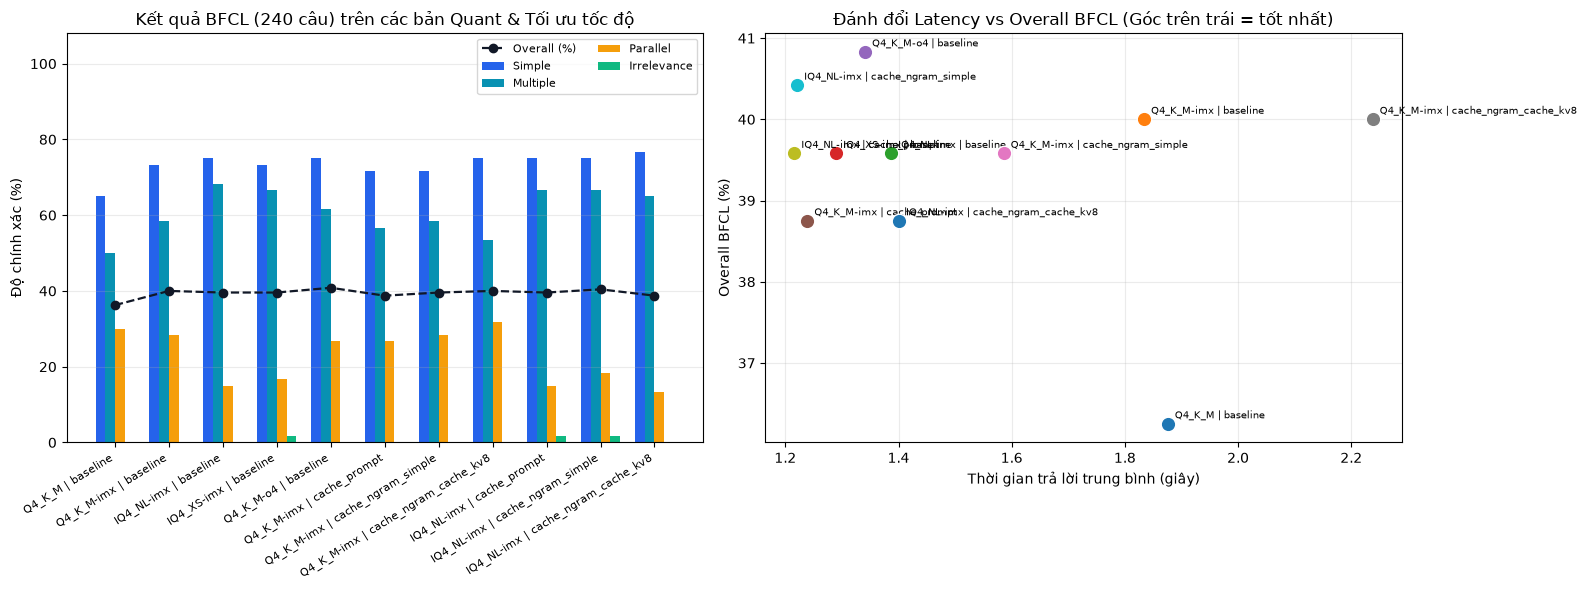

In [3]:
records = json.loads(RESULT_FILE.read_text(encoding="utf-8"))
df_bfcl = pd.DataFrame(records)

disp = pd.DataFrame({
    "Cấu hình": df_bfcl["run_id"],
    "File (MiB)": df_bfcl["size_mib"].map(lambda v: f"{v:.1f}"),
    "RAM đỉnh (MB)": df_bfcl["ram_peak_mb"].map(lambda v: f"{v:.0f}"),
    "Latency TB (s)": df_bfcl["mean_latency_s"].map(lambda v: f"{v:.2f}s"),
    "P95 (s)": df_bfcl["p95_latency_s"].map(lambda v: f"{v:.2f}s"),
    "Simple": df_bfcl["simple"].map(lambda v: f"{v*100:.1f}%"),
    "Multiple": df_bfcl["multiple"].map(lambda v: f"{v*100:.1f}%"),
    "Parallel": df_bfcl["parallel"].map(lambda v: f"{v*100:.1f}%"),
    "Irrelevance": df_bfcl["irrelevance"].map(lambda v: f"{v*100:.1f}%"),
    "Overall BFCL": df_bfcl["overall"].map(lambda v: f"{v*100:.1f}%"),
})
display(disp)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = np.arange(len(df_bfcl))
labels = df_bfcl["run_id"].tolist()

# Biểu đồ 1: Điểm BFCL từng nhóm
ax1 = axes[0]
w = 0.18
cats = [("simple", "Simple", "#2563eb"), ("multiple", "Multiple", "#0891b2"),
        ("parallel", "Parallel", "#f59e0b"), ("irrelevance", "Irrelevance", "#10b981")]
for i, (col, title, colr) in enumerate(cats):
    ax1.bar(x + (i - 1.5) * w, df_bfcl[col] * 100, w, label=title, color=colr)
ax1.plot(x, df_bfcl["overall"] * 100, "o--", color="#111827", lw=1.6, label="Overall (%)")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=32, ha="right", fontsize=8)
ax1.set_ylim(0, 108)
ax1.set_ylabel("Độ chính xác (%)")
ax1.set_title("Kết quả BFCL (240 câu) trên các bản Quant & Tối ưu tốc độ")
ax1.legend(loc="upper right", fontsize=8, ncol=2)
ax1.grid(axis="y", alpha=0.25)

# Biểu đồ 2: Đánh đổi Thời gian trả lời (s) vs Overall BFCL (%)
ax2 = axes[1]
for _, r in df_bfcl.iterrows():
    ax2.scatter(r["mean_latency_s"], r["overall"] * 100, s=110, edgecolor="white", zorder=3)
    ax2.annotate(r["run_id"], (r["mean_latency_s"], r["overall"] * 100),
                 xytext=(5, 4), textcoords="offset points", fontsize=7.5)
ax2.set_xlabel("Thời gian trả lời trung bình (giây)")
ax2.set_ylabel("Overall BFCL (%)")
ax2.set_title("Đánh đổi Latency vs Overall BFCL (Góc trên trái = tốt nhất)")
ax2.grid(alpha=0.25)

fig.tight_layout()
st.CHARTS_DIR.mkdir(exist_ok=True)
chart_path = st.CHARTS_DIR / "12_qwen25_05b_bfcl_comparison.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
print("Đã lưu biểu đồ tại:", chart_path)
plt.show()